CUSTOMER SEGMENTATION ANALYSIS
---------------------------------------------
Total customers: 200
Selected number of clusters: 6
Silhouette Score: 0.428

CUSTOMER SEGMENT PROFILES
           Age  Annual_Income  Spending_Score  Customer_Count
Cluster                                                      
0        56.33          54.27           49.07              45
1        26.79          57.10           48.13              39
2        41.94          88.94           16.97              33
3        32.69          86.54           82.13              39
4        25.00          25.26           77.61              23
5        45.52          26.29           19.38              21

MARKETING STRATEGIES
Cluster 0: Affordable trending products, bundles, and loyalty points
Cluster 1: Personalised recommendations and targeted incentives
Cluster 2: Personalised recommendations and targeted incentives
Cluster 3: Premium offers, loyalty rewards, and exclusive products
Cluster 4: Affordable trending product

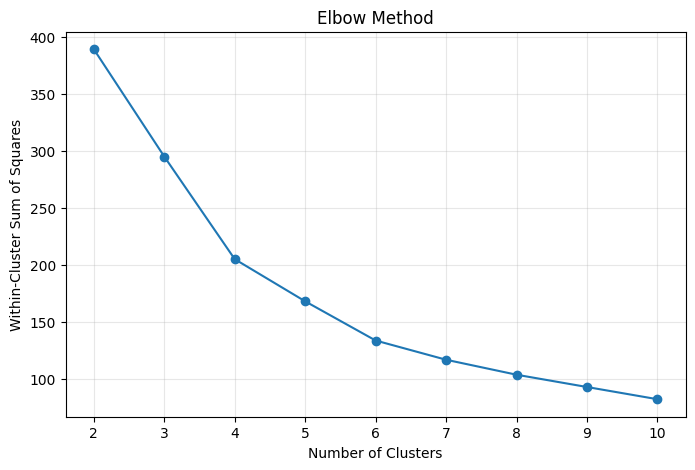

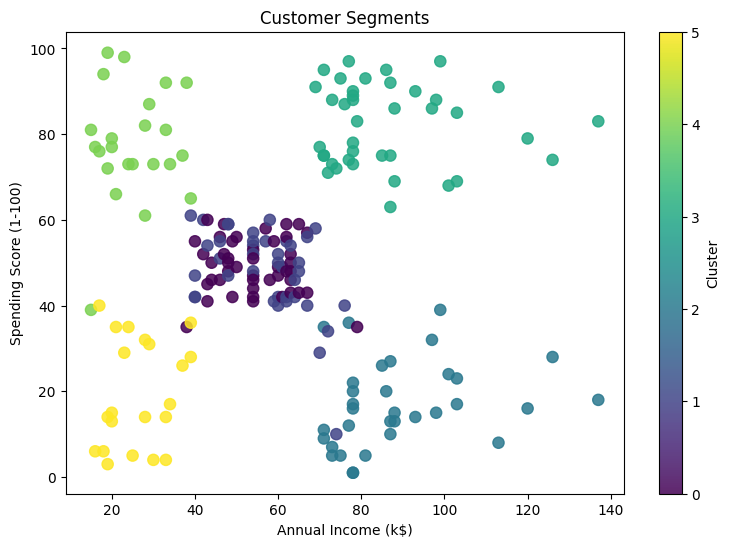

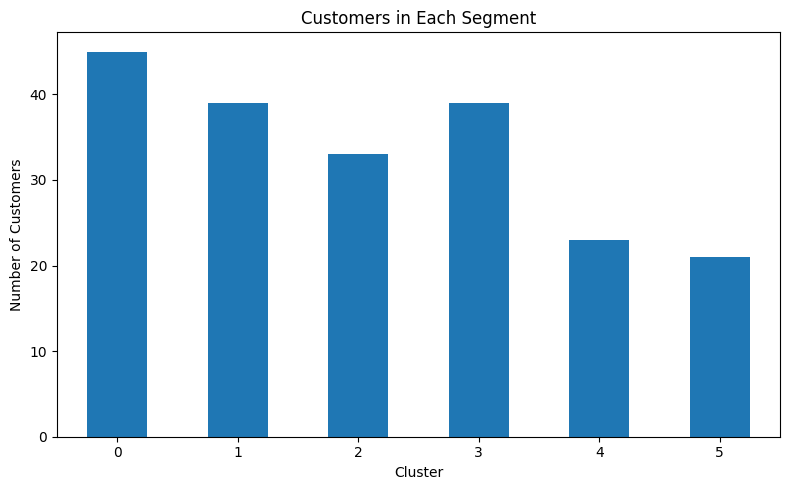


RESULT
K-Means identified 6 customer segments based on age, annual income, and spending score.
The cluster profiles and marketing suggestions can help businesses plan targeted campaigns.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

url = "https://raw.githubusercontent.com/selva86/datasets/master/Mall_Customers.csv"

try:
    df = pd.read_csv(url)
except Exception:
    url = "https://huggingface.co/SezarTheGreat/mall-customer-segmentation-kmeans/resolve/main/Mall_Customers.csv"
    df = pd.read_csv(url)

df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score"})

features = ["Age", "Annual_Income", "Spending_Score"]
X = df[features].copy()
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertias = []
scores = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    scores.append(silhouette_score(X_scaled, labels))

best_k = range(2, 11)[int(np.argmax(scores))]
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("CUSTOMER SEGMENTATION ANALYSIS")
print("-" * 45)
print("Total customers:", len(df))
print("Selected number of clusters:", best_k)
print("Silhouette Score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))

print("\nCUSTOMER SEGMENT PROFILES")
profile = df.groupby("Cluster")[features].mean().round(2)
profile["Customer_Count"] = df["Cluster"].value_counts().sort_index()
print(profile)

print("\nMARKETING STRATEGIES")
for cluster, row in profile.iterrows():
    income = row["Annual_Income"]
    spending = row["Spending_Score"]

    if income >= profile["Annual_Income"].median() and spending >= profile["Spending_Score"].median():
        strategy = "Premium offers, loyalty rewards, and exclusive products"
    elif income >= profile["Annual_Income"].median() and spending < profile["Spending_Score"].median():
        strategy = "Personalised recommendations and targeted incentives"
    elif income < profile["Annual_Income"].median() and spending >= profile["Spending_Score"].median():
        strategy = "Affordable trending products, bundles, and loyalty points"
    else:
        strategy = "Value deals, discounts, and budget-friendly promotions"

    print(f"Cluster {cluster}: {strategy}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=65,
    alpha=0.85)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments")
plt.colorbar(scatter, label="Cluster")
plt.show()

plt.figure(figsize=(8, 5))
profile["Customer_Count"].plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.title("Customers in Each Segment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nRESULT")
print(f"K-Means identified {best_k} customer segments based on age, annual income, and spending score.")
print("The cluster profiles and marketing suggestions can help businesses plan targeted campaigns.")